# Wine Quality Prediction — Reproduction Walkthrough

**Reproducing Ma et al. (2024),** *From vineyard to table: Uncovering wine quality for sales management through machine learning*, Journal of Business Research 176:114576. DOI: [10.1016/j.jbusres.2024.114576](https://doi.org/10.1016/j.jbusres.2024.114576)

Dataset: [UCI Wine Quality (Red)](https://archive.ics.uci.edu/dataset/186/wine+quality) — 1,599 samples, 11 physicochemical features, quality score 0–10.

This notebook is a linear walkthrough of the reproduction. It calls the same functions in `src/` that `run_all.py` uses — no separate logic.

> **Runtime note:** the cells below use **2 CV repeats** so the notebook finishes in about a minute. The project's reported results use the paper's full protocol of **10 repeats** (`python run_all.py`), so numbers here will differ slightly from those in the README and the report.
>
> For that reason this notebook writes its tables and figures to a scratch folder (`notebooks/_scratch_outputs/`), never to `results/`. Otherwise a quick 2-repeat run here would silently overwrite the canonical 10-repeat numbers the write-up quotes.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import pandas as pd

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

# Scratch output folder, so this 2-repeat run never overwrites the canonical
# 10-repeat results in ../results/ that the README and report quote.
SCRATCH = Path.cwd() / "_scratch_outputs"
SCRATCH.mkdir(exist_ok=True)
print("notebook outputs ->", SCRATCH)

notebook outputs -> /Users/AIRUS/Documents/ML Essentials/wine-quality-ml-project/notebooks/_scratch_outputs


## 1. Load the data and verify it matches the paper

The paper uses 1,599 red *Vinho Verde* samples with 11 features. Quality classes 0, 1, 2, 9 and 10 are always empty — which is why the paper omits them from its tables.

In [2]:
from preprocessing import load_red_wine_xy

X, y, feature_columns, df = load_red_wine_xy()

print("shape:", df.shape)
print("features:", len(feature_columns))
display(df.head())

print("\nQuality class distribution:")
df["quality"].value_counts().sort_index()

shape: (1599, 12)
features: 11


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5



Quality class distribution:


quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

Classes 3 and 8 have only 10 and 18 samples out of 1,599. This imbalance is the single biggest driver of the results below, and it is the limitation the paper itself acknowledges.

## 2. The base learners

The paper's ensemble is SVM + RNN + ELM + Random Forest. Two are outside a classical-ML syllabus, so:

| Paper | Ours | Why |
|---|---|---|
| SVM | `SVC` (unchanged) | already classical ML |
| Random Forest | `RandomForestClassifier` (unchanged) | already classical ML |
| RNN | `GradientBoostingClassifier` | closest in-syllabus analogue to iterative refinement, no backprop-through-time |
| ELM | `MLPClassifier` | still a neural net, but trained by standard backprop (ELM is not) |

Each learner is wrapped in a `Pipeline` so that **min-max scaling is fit on the training fold only** — scaling the whole dataset before cross-validation would leak test-fold information.

In [3]:
from base_learners import get_base_learners

for name, model in get_base_learners().items():
    print(f"{name:10s} -> {model.steps[-1][1].__class__.__name__}")

SVM        -> CalibratedClassifierCV
RF         -> RandomForestClassifier
MLP        -> MLPClassifier
GradBoost  -> GradientBoostingClassifier


## 3. Run the ensemble

`run_repeated_cv` fits every learner under a shared stratified 10-fold split, computes the paper's weights (Eqs. 4–9), and combines predictions two ways:

- **Soft vote** — `P = Σ wᵢ · Pᵢ`, then `argmax`. The literal reading of Eq. (1) as a weighted *sum* of scores.
- **Hard vote** — each learner one-hot votes its label with weight `wᵢ`. What Eq. (1) degenerates to if `ŷᵢ` is a discrete label.

In [4]:
from ensemble import run_repeated_cv

results = run_repeated_cv(X, y, n_repeats=2)  # 2 repeats for notebook speed
print("done — pooled predictions over", len(results["per_repeat"]), "repeats")

done — pooled predictions over 2 repeats


## 4. The weights (Eqs. 4–9), and why they matter

`w_i = 0.5 · (w_accuracy_i + w_diversity_i)`, where the accuracy weight is the normalised inverse CV error and the diversity weight is the normalised sum of Euclidean distances between error vectors.

In [5]:
from ensemble import weight_concentration

r0 = results["per_repeat"][0]
weights_df = pd.DataFrame({
    "w_accuracy": r0["weights_accuracy"],
    "w_diversity": r0["weights_diversity"],
    "w_combined": r0["weights"],
    "cv_error": r0["cv_error"],
})
display(weights_df.round(4))

print("Weight concentration vs. a uniform 0.25 each:")
for k, v in weight_concentration(r0["weights"]).items():
    print(f"  {k}: {v}")

,w_accuracy,w_diversity,w_combined,cv_error
SVM,0.2223,0.2511,0.2367,0.3796
RF,0.2953,0.2443,0.2698,0.2858
MLP,0.2209,0.2504,0.2356,0.3821
GradBoost,0.2615,0.2542,0.2579,0.3227


Weight concentration vs. a uniform 0.25 each:
  n_learners: 4
  uniform_weight: 0.25
  max_weight: 0.2697942857032431
  min_weight: 0.23564251718195944
  weight_spread: 0.034151768521283654
  max_abs_deviation_from_uniform: 0.019794285703243097


**Key observation:** the weights barely move away from uniform. Eqs. (5) and (9) normalise inverse errors and pairwise error distances, and neither discriminates strongly when the learners have broadly similar error rates. The paper's own Table 8 shows the same pattern (0.2516 / 0.2286 / 0.2168 / 0.3030).

With weights this flat, the ensemble behaves close to a plain average of its members — so it lands *between* the strongest and weakest learner rather than above the strongest.

## 5. Results: does the ensemble beat its base learners?

In [6]:
from evaluate import evaluate_all

all_results, comparison = evaluate_all(
    results["pooled_true"],
    results["pooled_preds"],
    results["pooled_ensemble"],
    results["classes"],
    pooled_ensemble_hard=results["pooled_ensemble_hard"],
    tables_dir=SCRATCH,   # write to scratch, not results/
    figures_dir=SCRATCH,
)

pd.read_csv(SCRATCH / "model_accuracy_summary.csv")

,model,overall_accuracy_pct,rank
0,RF,71.450907,1
1,Ensemble (hard vote),70.012508,2
2,Ensemble (soft vote),69.199500,3
3,GradBoost,67.417136,4
4,SVM,62.195122,5
5,MLP,61.038149,6


## 6. Confusion matrix and per-class metrics for the ensemble

Note on terminology: the paper labels its per-class metric "precision", but its own worked example (Eq. 14) divides by the *actual* class total — that is recall. We report both, and flag which one matches the published figures.

In [7]:
ensemble_cm, ensemble_metrics = all_results["Ensemble"]
display(ensemble_cm)
display(ensemble_metrics.round(2))

,pred_3,pred_4,pred_5,pred_6,pred_7,pred_8
true_3,0,1,15,4,0,0
true_4,1,1,74,28,2,0
true_5,0,3,1108,246,5,0
true_6,2,3,295,903,72,1
true_7,0,0,22,178,197,1
true_8,0,0,0,21,11,4


,class,n_actual,precision,sensitivity_recall,specificity,precision_paper_definition_pct
0,3,20,0.00,0.00,99.91,0.00
1,4,106,12.50,0.94,99.77,0.94
2,5,1362,73.18,81.35,77.89,81.35
3,6,1276,65.43,70.77,75.18,70.77
4,7,398,68.64,49.50,96.79,49.50
5,8,36,66.67,11.11,99.94,11.11


## 7. Comparison against the published benchmarks

,class,cortez_2009_pct,ma_2024_pct,our_reproduction_pct
0,3,0.0,33.33,0.00
1,4,20.0,63.16,0.94
2,5,67.5,84.80,81.35
3,6,57.7,88.06,70.77
4,7,58.6,77.08,49.50
5,8,0.0,50.00,11.11
6,overall,NaN,89.73,69.20


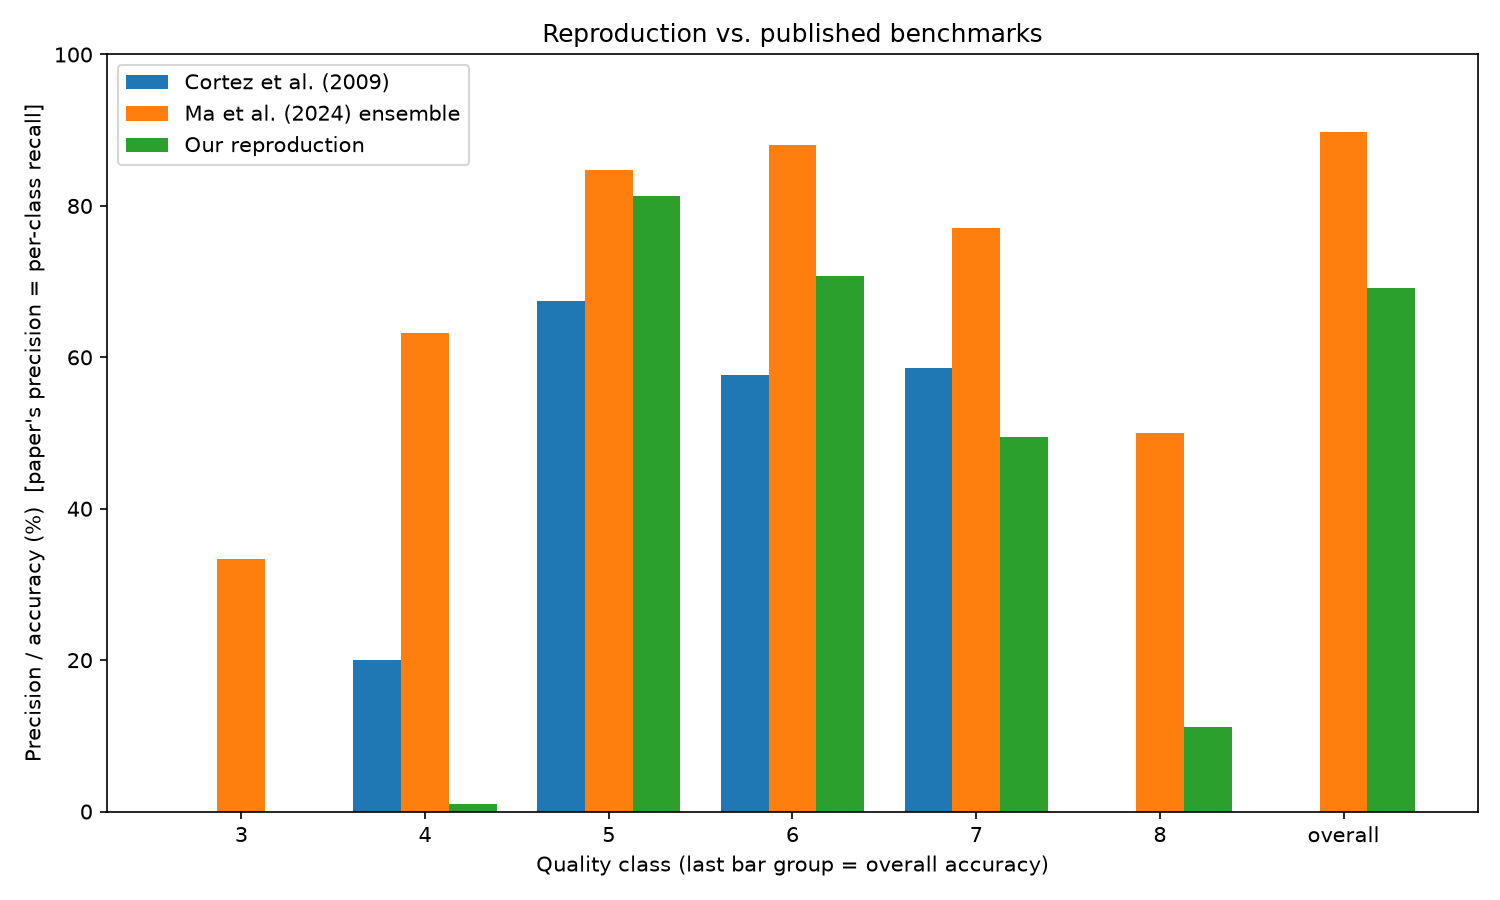

In [8]:
display(comparison.round(2))

# The chart this notebook just generated (2 repeats, in the scratch folder).
# The canonical 10-repeat version lives at ../results/figures/accuracy_comparison.png
from IPython.display import Image
Image(filename=str(SCRATCH / "accuracy_comparison.png"))

## 8. Why we cannot reach the paper's 89.73%

Two independent checks, both computed from the paper's own printed numbers.

**(a) Their Table 9 confusion matrix.** Summing every cell gives the size of the evaluation set, and the diagonal gives the accuracy it implies.

In [9]:
from evaluate import paper_table9_reconciliation

recon, per_class_check = paper_table9_reconciliation(tables_dir=SCRATCH)
display(recon)
display(per_class_check)

,quantity,value
0,implied_test_set_size,491
1,full_dataset_size,1599
2,implied_fraction_of_dataset_pct,30.71
3,correct_predictions_on_diagonal,403
4,implied_overall_accuracy_pct,82.08
5,paper_reported_overall_accuracy_pct,89.73
6,discrepancy_pct_points,7.65
7,n_per_class_matching_column_wise,4
8,literature_accuracy_range_pct,62.0-72.0


,class,paper_reported_pct,recomputed_column_wise_pct,recomputed_row_wise_pct,column_wise_matches
0,3,33.33,33.33,33.33,True
1,4,63.16,63.16,54.55,True
2,5,84.80,84.80,86.93,True
3,6,88.06,88.50,87.62,True
4,7,77.08,61.67,60.66,False
5,8,50.00,60.00,75.00,False


The matrix sums to roughly 490 samples — about 30% of the dataset, i.e. a single hold-out split rather than the 100-run cross-validation the text describes. Our protocol evaluates all 1,599 samples ten times over, which is strictly harder.

The per-class check also confirms the metric orientation: their published percentages reproduce **column-wise** (TP ÷ actual-class total = recall), not row-wise.

> **Caveat:** the Table 9 cells were transcribed by eye from the printed PDF and may contain reading errors — which is the most likely explanation for the two classes that do not match. This is reported as "could not reconcile", not as a claim that the paper is wrong.

**(b) Their Table 8 weights applied to their Tables 4–7 accuracies.**

In [10]:
from evaluate import paper_internal_consistency_check

our_acc = 100.0 * (results["pooled_ensemble"] == results["pooled_true"]).mean()
paper_internal_consistency_check(our_ensemble_accuracy=our_acc, tables_dir=SCRATCH)

,quantity,value
0,weight_sum_total,1.000
1,max_abs_deviation_from_uniform_weight,0.053
2,best_single_base_learner_pct,80.710
3,weighted_average_of_base_accuracies_pct,67.520
4,paper_reported_ensemble_pct,89.730
5,gap_vs_weighted_average_pct_points,22.210
6,gap_vs_best_base_learner_pct_points,9.020
7,our_ensemble_pct,69.200
8,our_gap_vs_their_weighted_average_pct_points,1.680


## 9. Conclusion

- The reproduction recovers the **shape** of the paper's findings: mid-tier classes (5, 6) are predicted well above the Cortez et al. (2009) baseline, and the extreme classes (3, 4, 8) remain hardest.
- It does **not** recover the magnitude. Our ensemble lands in the high 60s / low 70s, inside the 62–72% band typically reported for this 6-class task, while the paper reports 89.73%.
- The paper's near-uniform weights mean its ensemble should behave close to an average of its base learners — which is what we observe in our own run, and what its own published numbers imply.

Full write-up: [`report/methodology.md`](../report/methodology.md).